In [41]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit import transpile
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import ZGate

# ES 3 

Design a phase oracle and apply it in a proper quantum circuit to solve the following
satisfiability problem.
Let’sconsider two inputs a and b,representable with two bits for each. Find the proper
values for a and b to satisfy the following conditions:
• a + b = 4;
• a ̸= b.

## Reptetition number:

In [ ]:

N = 64
M = 1

theta = np.arcsin(np.sqrt(M / N))
r_opt = np.pi / (4 * theta) - 0.5

print("Theta:", theta)
print("Optimal iterations:", r_opt)

Theta: 0.1253278311680654
Optimal iterations: 5.766749819872207


### Grover's Algorthm

In [ ]:

def phase_oracle() -> QuantumCircuit:

    oracle = QuantumCircuit(4, name="SAT_oracle")

    # Convert MCX operations into phase operations (HXH=Z)
    oracle.h(3)

    # Satisfaction of |0111>
    oracle.x(0)
    oracle.mcx([0, 1, 2], 3)
    oracle.x(0)

    # Satisfaction of |1101>
    oracle.x(2)
    oracle.mcx([0, 1, 2], 3)
    oracle.x(2)

    # Complete transformation
    oracle.h(3)

    return oracle


def diffuser_4qubit() -> QuantumCircuit:

    diff = QuantumCircuit(4, name="diffuser_4qubit")

    diff.h([0,1,2,3])
    diff.x([0,1,2,3])

    diff.h(3)
    diff.mcx([0,1,2], 3)
    diff.h(3)

    diff.x([0,1,2,3])
    diff.h([0,1,2,3])

    return diff


def grover_sat() -> QuantumCircuit:

    qc = QuantumCircuit(4,4)

    # Initialization:
    qc.h([0,1,2,3])

    # Grover iteration:
    for i in range(2):
        qc.compose(phase_oracle(), inplace=True)
        qc.compose(diffuser_4qubit(), inplace=True)

    # Measurements:
    qc.measure([0,1,2,3], [0,1,2,3])

    return qc

### Code simulation

/opt/anaconda3/envs/quantum_computing/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'1011': 495, '0110': 7, '1110': 470, '1111': 6, '0101': 5, '0111': 7, '1100': 6, '0011': 5, '0001': 6, '1101': 2, '1001': 4, '0010': 3, '1010': 1, '1000': 5, '0000': 2}


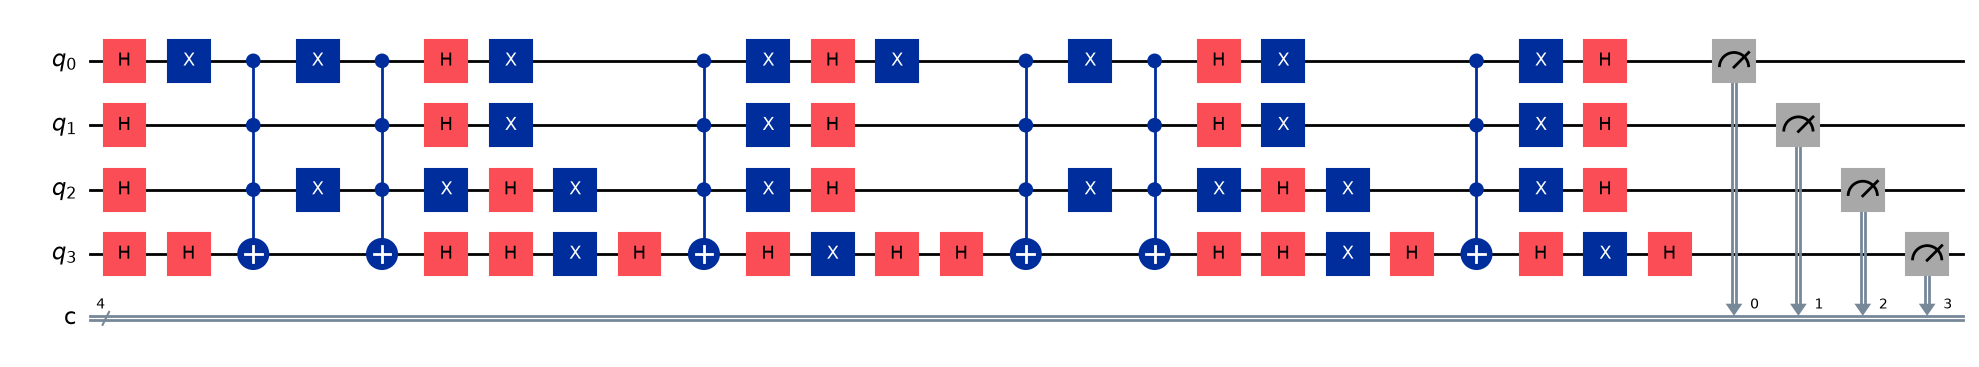

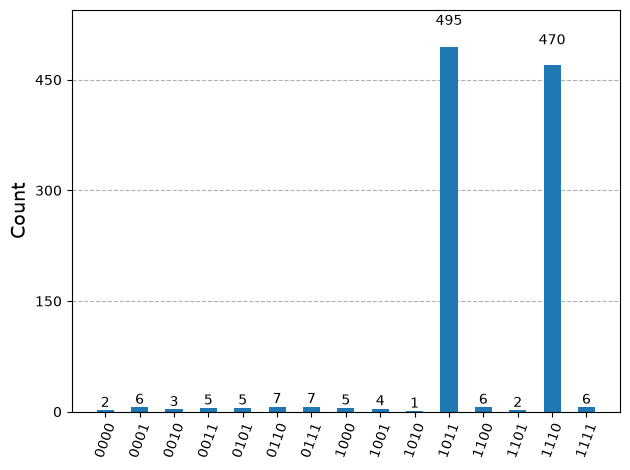

In [ ]:

simulator = BasicSimulator()

qc = grover_sat()

compiled = transpile(qc, simulator)

result = simulator.run(compiled, shots=1024).result()
counts = result.get_counts()

print(counts)
display(qc.draw("mpl", fold=-1))
display(plot_histogram(counts))


# ES OPRTIONAL 3.2

Design a phase oracles for a three-input satisfiability problem.
Let’sconsider three inputs a,b,c, representable with two bits for each. Find the proper
values for a,b and c to satisfy the following conditions:

    • a + b = 5;
    • b + c = 3;
    • a + c = 2;
    •a ̸= b ̸= c.

In [50]:
def phase_oracle_6qubit() -> QuantumCircuit: 

    oracle = QuantumCircuit(6, name="satisfaction_oracle")

    # Mark |101100> :
    oracle.x([1,4,5]) 
    oracle.mcp(np.pi, [0, 1, 2, 4, 5], 3) 
    
    # Alternative method 
    #multi_cz = ZGate().control(
    #    5,
    #    ctrl_state="00101")
    #oracle.append(multi_cz, [0, 1, 2, 4, 5, 3])

    oracle.x([1,4,5])

    return oracle

def diffuser_6qubit() -> QuantumCircuit:

    diff = QuantumCircuit(6, name="diffuser_6qubit")
    
    diff.h([0,1,2,3,4,5])
    diff.x([0,1,2,3,4,5])
    
    diff.mcp(np.pi, [0,1,2,3,4], 5)
    
    diff.x([0,1,2,3,4,5])
    diff.h([0,1,2,3,4,5])
    
    return diff

def grover_sat_3inputs() -> QuantumCircuit:

    qc = QuantumCircuit(6, 6)

    # Initialization:
    qc.h(range(6))

    # 6 Grover iteration:
    for rep in range(6):
        qc.compose(phase_oracle_6qubit(), inplace=True)
        qc.compose(diffuser_6qubit(), inplace=True)

    # Measurements:
    qc.measure(range(6), range(6))

    return qc

### Test

{'001101': 1019, '111010': 1, '110010': 1, '111011': 1, '001001': 1, '011111': 1}


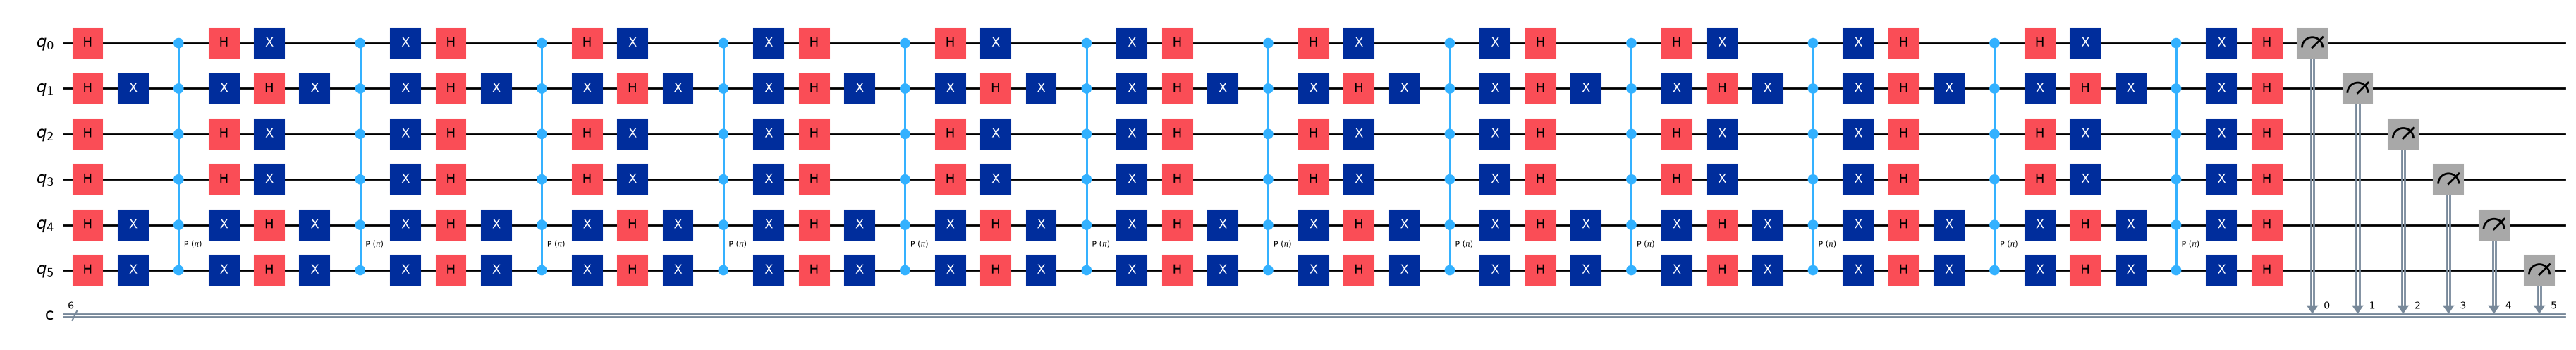

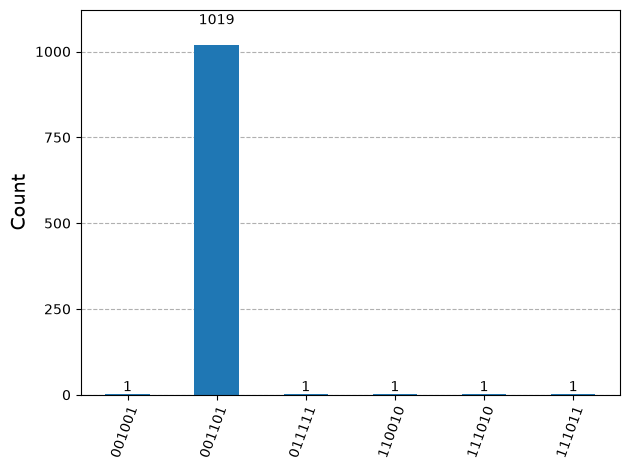

In [53]:
simulator = BasicSimulator()

qc = grover_sat_3inputs()

compiled = transpile(qc, simulator)
result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()

print(counts)
display(qc.draw("mpl", fold=-1))
display(plot_histogram(counts))